In [4]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
dataset_dir= "/content/drive/MyDrive/IE643-Project/dataset"

damaged_dir= os.path.join(dataset_dir,"damaged")
mask_dir= os.path.join(dataset_dir,"masks")
clean_dir= os.path.join(dataset_dir,"clean")

print("damaged directory:",damaged_dir)
print("checking mask exist", mask_dir)

print("Damaged exists:", os.path.exists(damaged_dir))
print("Masks exists:", os.path.exists(mask_dir))
print("Clean exists:", os.path.exists(clean_dir))


damaged directory: /content/drive/MyDrive/IE643-Project/dataset/damaged
checking mask exist /content/drive/MyDrive/IE643-Project/dataset/masks
Damaged exists: True
Masks exists: True
Clean exists: True


In [7]:
damaged_files= sorted([
    f for f in os.listdir(damaged_dir)
    if f.lower().endswith((".png",".jpg", ".jpeg"))

])
mask_files= sorted([
    f for f in os.listdir(mask_dir)
    if f.lower().endswith((".png",".jpg", ".jpeg"))

])

print("damaged images:", len(damaged_files))
print("mask images:", len(mask_files))

print("\nDamaged images:")
print(damaged_files[:10])

print("\nMasks:")
print(mask_files[:10])

damaged images: 6794
mask images: 6794

Damaged images:
['000000_00_combined.jpg', '000000_01_blur.jpg', '000000_02_paint.jpg', '000001_00_blur.jpg', '000001_01_combined.jpg', '000001_02_paint.jpg', '000002_00_combined.jpg', '000002_01_paint.jpg', '000002_02_cut.jpg', '000003_00_combined.jpg']

Masks:
['000000_00_combined.png', '000000_01_blur.png', '000000_02_paint.png', '000001_00_blur.png', '000001_01_combined.png', '000001_02_paint.png', '000002_00_combined.png', '000002_01_paint.png', '000002_02_cut.png', '000003_00_combined.png']


In [8]:
mask_dict = {
    Path(f).stem: os.path.join(mask_dir, f)
    for f in mask_files
}

pairs = []

for f in damaged_files:

    stem = Path(f).stem

    if stem in mask_dict:

        pairs.append({
            "name": stem,
            "image": os.path.join(damaged_dir, f),
            "mask": mask_dict[stem]
        })

print("Total image-mask pairs:", len(pairs))

unmatched = [
    f for f in damaged_files
    if Path(f).stem not in mask_dict
]

print("Unmatched damaged images:", len(unmatched))

if unmatched:
    print(unmatched[:10])

Total image-mask pairs: 6794
Unmatched damaged images: 0


In [9]:
df = pd.DataFrame(pairs)

df = df[["name", "image", "mask"]]

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Shuffle the rows
split_df = split_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 4755
Validation: 1019
Test: 1020


Testing with Unet

In [10]:
split_dir = os.path.join(
    dataset_dir,
    "splits"
)

os.makedirs(
    split_dir,
    exist_ok=True
)

# Convert absolute paths to relative paths
split_df["image"] = split_df["image"].apply(
    lambda x: os.path.relpath(x, dataset_dir)
)

split_df["mask"] = split_df["mask"].apply(
    lambda x: os.path.relpath(x, dataset_dir)
)

csv_path = os.path.join(
    split_dir,
    "dataset_split.csv"
)

split_df.to_csv(
    csv_path,
    index=False
)

print("Dataset split saved to:")
print(csv_path)

Dataset split saved to:
/content/drive/MyDrive/IE643-Project/dataset/splits/dataset_split.csv


In [11]:
#for faster training and so that doesnot fetch eveyrtime from drive as was taking so much time for even 1 epoch
import shutil

local_dataset = "/content/IE643_dataset"

shutil.copytree(
    damaged_dir,
    os.path.join(local_dataset, "damaged"),
    dirs_exist_ok=True
)

shutil.copytree(
    mask_dir,
    os.path.join(local_dataset, "masks"),
    dirs_exist_ok=True
)

print("Dataset copied")

Dataset copied


In [12]:
def local_paths(df):

    df = df.copy()

    df["image"] = df["image"].apply(
        lambda x: os.path.join(
            local_dataset,
            x.split("/")[-2],
            x.split("/")[-1]
        )
    )

    df["mask"] = df["mask"].apply(
        lambda x: os.path.join(
            local_dataset,
            x.split("/")[-2],
            x.split("/")[-1]
        )
    )

    return df


train_df = local_paths(train_df)
val_df = local_paths(val_df)
test_df = local_paths(test_df)

In [13]:
img_size = 256
batch_size = 4

In [14]:
def load_image_mask(image_path, mask_path):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(
        image,
        channels=3
    )
    image.set_shape([None, None, 3])

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(
        mask,
        channels=1
    )
    mask.set_shape([None, None, 1])

    image = tf.image.resize(
        image,
        [img_size, img_size],
        method="bilinear"
    )

    mask = tf.image.resize(
        mask,
        [img_size, img_size],
        method="nearest"
    )

    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask > 0, tf.float32)

    return image, mask

In [15]:
#tensorflow datasets

def createdataset(df, shuffle=False):

    image_paths = df["image"].values
    mask_paths = df["mask"].values

    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=500,
            seed=42
        )

    ds = ds.map(
        load_image_mask,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(batch_size)
    ds = ds.prefetch(1)

    return ds


In [16]:
train_ds = createdataset(train_df, shuffle=True)
val_ds = createdataset(val_df)
test_ds = createdataset(test_df)

In [17]:
#testing one batch
%time images, masks = next(iter(train_ds))

print(images.shape)
print(masks.shape)

CPU times: user 35.4 ms, sys: 10.5 ms, total: 45.8 ms
Wall time: 55.9 ms
(4, 256, 256, 3)
(4, 256, 256, 1)


In [18]:
def local_paths(df):

    df = df.copy()

    df["image"] = df["image"].apply(
        lambda x: os.path.join(
            local_dataset,
            "damaged",
            os.path.basename(x)
        )
    )

    df["mask"] = df["mask"].apply(
        lambda x: os.path.join(
            local_dataset,
            "masks",
            os.path.basename(x)
        )
    )

    return df


train_df = local_paths(train_df)
val_df = local_paths(val_df)
test_df = local_paths(test_df)

print(train_df.iloc[0]["image"])
print(train_df.iloc[0]["mask"])

/content/IE643_dataset/damaged/001391_00_combined.jpg
/content/IE643_dataset/masks/001391_00_combined.png


In [19]:
image_path = train_df.iloc[0]["image"]
mask_path = train_df.iloc[0]["mask"]

print(image_path)
print(mask_path)

image = tf.io.read_file(image_path)
image = tf.image.decode_jpeg(image, channels=3)

mask = tf.io.read_file(mask_path)
mask = tf.image.decode_png(mask, channels=1)

print(image.shape)
print(mask.shape)

/content/IE643_dataset/damaged/001391_00_combined.jpg
/content/IE643_dataset/masks/001391_00_combined.png
(256, 256, 3)
(256, 256, 1)


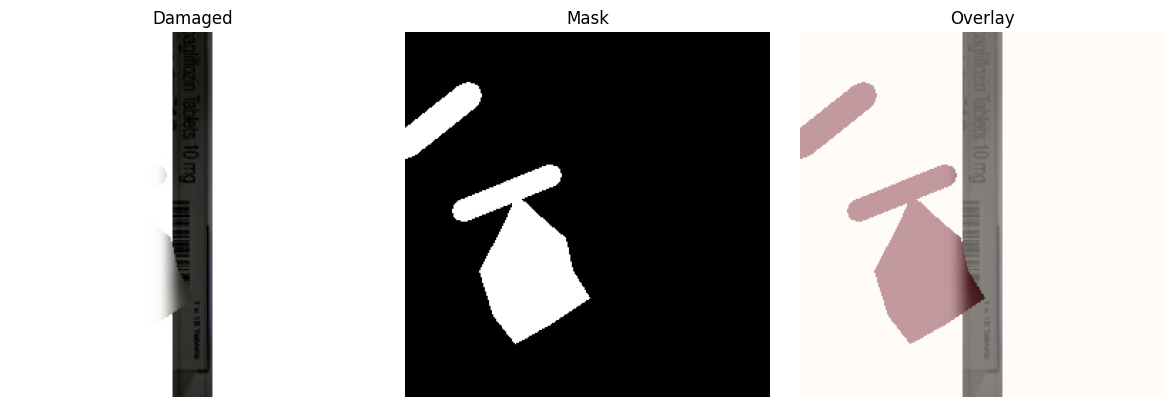

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Damaged")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask[:, :, 0], cmap="gray")
plt.title("Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask[:, :, 0], cmap="Reds", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

# U-net imlementation

In [21]:
def conv_block(x, filters):

    x = layers.Conv2D(
        filters, 3, padding="same"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters, 3, padding="same"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x

In [22]:
def unet():

    inputs = layers.Input(
        shape=(img_size, img_size, 3)
    )

    # encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D()(c4)

    # bottleneck
    c5 = conv_block(p4, 512)

    # decoder
    u6 = layers.Conv2DTranspose(
        256, 2, strides=2, padding="same"
    )(c5)

    u6 = layers.concatenate([u6, c4])
    c6 = conv_block(u6, 256)

    u7 = layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(c6)

    u7 = layers.concatenate([u7, c3])
    c7 = conv_block(u7, 128)

    u8 = layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c7)

    u8 = layers.concatenate([u8, c2])
    c8 = conv_block(u8, 64)

    u9 = layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(c8)

    u9 = layers.concatenate([u9, c1])
    c9 = conv_block(u9, 32)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid"
    )(c9)

    return keras.Model(inputs, outputs)

In [23]:
model = unet()

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,873 (29.65 MB)

 Trainable params: 7,765,985 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [24]:
def dice_coef(y_true, y_pred):

    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    return (
        2.0 * intersection + 1e-7
    ) / (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
        + 1e-7
    )

In [25]:
def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

In [26]:
bce = keras.losses.BinaryCrossentropy()
#This is useful here because the damaged region may occupy a relatively small part of the image, so relying only on pixel-wise BCE may not be enough.
def combined_loss(y_true, y_pred):

    return (
        bce(y_true, y_pred)
        + dice_loss(y_true, y_pred)
    )

In [27]:
def iou(y_true, y_pred):

    y_true = tf.reshape(y_true, [-1])

    y_pred = tf.cast(
        tf.reshape(y_pred, [-1]) > 0.5,
        tf.float32
    )

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    union = (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
        - intersection
    )

    return (
        intersection + 1e-7
    ) / (
        union + 1e-7
    )

In [28]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=combined_loss,
    metrics=[
        dice_coef,
        iou
    ]
)

the model knows:
Optimizer: Adam,
Learning rate: 0.0001,
Loss: BCE + Dice Loss,
Metrics: Dice and IoU

In [29]:
callbacks = [

    keras.callbacks.ModelCheckpoint(
        "unet_best.keras",
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=8,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3
    )
]

In [30]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
1189/1189 ━━━━━━━━━━━━━━━━━━━━ 256s 180ms/step - dice_coef: 0.3478 - iou: 0.4486 - loss: 0.9331 - val_dice_coef: 0.4729 - val_iou: 0.5182 - val_loss: 0.6740 - learning_rate: 1.0000e-04
Epoch 2/30
1189/1189 ━━━━━━━━━━━━━━━━━━━━ 210s 162ms/step - dice_coef: 0.6614 - iou: 0.6937 - loss: 0.4401 - val_dice_coef: 0.7677 - val_iou: 0.7599 - val_loss: 0.2997 - learning_rate: 1.0000e-04
Epoch 3/30
1189/1189 ━━━━━━━━━━━━━━━━━━━━ 192s 162ms/step - dice_coef: 0.8174 - iou: 0.7861 - loss: 0.2453 - val_dice_coef: 0.8457 - val_iou: 0.7940 - val_loss: 0.2102 - learning_rate: 1.0000e-04
Epoch 4/30
1189/1189 ━━━━━━━━━━━━━━━━━━━━ 192s 162ms/step - dice_coef: 0.8757 - iou: 0.8296 - loss: 0.1743 - val_dice_coef: 0.8710 - val_iou: 0.8218 - val_loss: 0.1802 - learning_rate: 1.0000e-04
Epoch 5/30
1189/1189 ━━━━━━━━━━━━━━━━━━━━ 202s 162ms/step - dice_coef: 0.9002 - iou: 0.8507 - loss: 0.1436 - val_dice_coef: 0.8900 - val_iou: 0.8317 - val_loss: 0.1582 - learning_rate: 1.0000e-04
Epoch 6/30
1189/1189

In [31]:
test_results = model.evaluate(
    test_ds,
    verbose=1
)

print("Test Loss:", test_results[0])
print("Test Dice:", test_results[1])
print("Test IoU:", test_results[2])

255/255 ━━━━━━━━━━━━━━━━━━━━ 14s 56ms/step - dice_coef: 0.9477 - iou: 0.9072 - loss: 0.0888
Test Loss: 0.08880153298377991
Test Dice: 0.9477357864379883
Test IoU: 0.9072408080101013


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


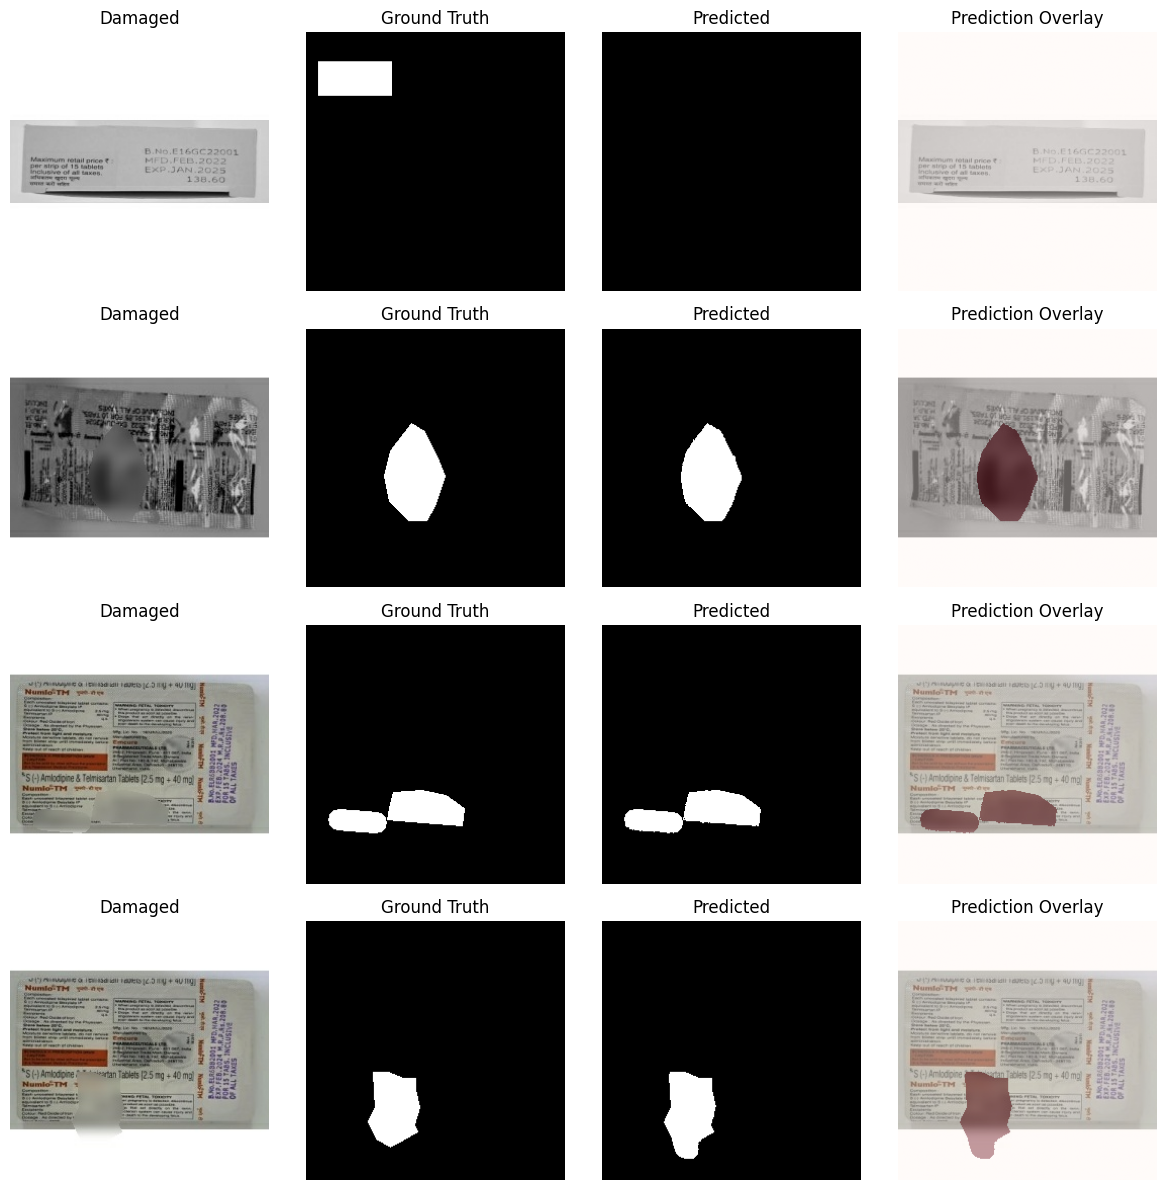

In [32]:
# Visualize U-Net predictions

images, true_masks = next(iter(test_ds))
pred_masks = model.predict(images)

plt.figure(figsize=(12, 12))

for i in range(4):

    plt.subplot(4, 4, i*4 + 1)
    plt.imshow(images[i])
    plt.title("Damaged")
    plt.axis("off")

    plt.subplot(4, 4, i*4 + 2)
    plt.imshow(true_masks[i, :, :, 0], cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(4, 4, i*4 + 3)
    plt.imshow(pred_masks[i, :, :, 0] > 0.5, cmap="gray")
    plt.title("Predicted")
    plt.axis("off")

    plt.subplot(4, 4, i*4 + 4)
    plt.imshow(images[i])
    plt.imshow(pred_masks[i, :, :, 0] > 0.5, cmap="Reds", alpha=0.4)
    plt.title("Prediction Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
# Save U-Net model and results

results_dir = "/content/drive/MyDrive/IE643-Project/results/unet"

os.makedirs(results_dir, exist_ok=True)

# Save model
model.save(
    os.path.join(results_dir, "unet_best.keras")
)

# Save test results
results = pd.DataFrame({
    "model": ["U-Net"],
    "test_loss": [test_results[0]],
    "test_dice": [test_results[1]],
    "test_iou": [test_results[2]]
})

results.to_csv(
    os.path.join(results_dir, "unet_results.csv"),
    index=False
)

print("U-Net saved.")
print(results)

U-Net saved.
   model  test_loss  test_dice  test_iou
0  U-Net   0.088802   0.947736  0.907241
